## <div align="center"> TUGAS LAB IS388 Data Analysis </div>
## <div align="center"> WEEK [04]: [Data Preprocessing]</div>
#### <div align="center"> Semester Ganjil 2024/2025 </div>
---

In [5]:
import datetime
import uuid

studentName = "Joyandro Gerard Diasz"
studentNIM = "00000158474"
studentClass = "B"

In [6]:
myDate = datetime.datetime.now()
myDevice = str(uuid.uuid1())

print("Name: \t\t{}".format(studentName))
print("NIM: \t\t{}".format(studentNIM))
print("NIM: \t\t{}".format(studentClass))
print("Start: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Joyandro Gerard Diasz
NIM: 		00000158474
NIM: 		B
Start: 		2026-09-15 12:07:14.813178
Device ID: 	50eec467-b0c3-11f1-824e-83db8f6f1918


---

## <div align="center"> Unguided Lab </div>

### Enter Unguided Lab Code Here:

In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Dataset dapat dibuka dari folder Week_04 atau dari root proyek.
possible_paths = [Path("superstore_sales.csv"), Path("Week_04") / "superstore_sales.csv"]
csv_path = next((path for path in possible_paths if path.is_file()), None)
if csv_path is None:
    raise FileNotFoundError("superstore_sales.csv tidak ditemukan di direktori kerja atau Week_04.")

df = pd.read_csv(csv_path)
print("Dataset:", csv_path)
print("Bentuk awal:", df.shape)
print("Nilai kosong per kolom:")
print(df.isna().sum().loc[lambda counts: counts > 0])
display(df.head())

Dataset: superstore_sales.csv
Bentuk awal: (9800, 18)
Nilai kosong per kolom:
Postal Code    11
dtype: int64


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


## <div align="center"> Question 01 </div>

In [8]:
# Menghapus baris yang memiliki nilai kosong.
shape_before = df.shape
missing_before = int(df.isna().sum().sum())
states_before = set(df["State"].dropna().unique())
df = df.dropna().copy()

print("Bentuk sebelum:", shape_before)
print("Bentuk sesudah:", df.shape)
print("Nilai kosong sebelum:", missing_before)
print("Nilai kosong sesudah:", int(df.isna().sum().sum()))
print("State yang hilang:", sorted(states_before - set(df["State"].unique())))

Bentuk sebelum: (9800, 18)
Bentuk sesudah: (9789, 18)
Nilai kosong sebelum: 11
Nilai kosong sesudah: 0
State yang hilang: ['Vermont']


## <div align="center"> Question 02 </div>

In [9]:
# Menghapus kolom yang memiliki setidaknya satu nilai kosong.
shape_before = df.shape
df = df.dropna(axis=1)

print("Bentuk sebelum:", shape_before)
print("Bentuk sesudah:", df.shape)

Bentuk sebelum: (9789, 18)
Bentuk sesudah: (9789, 18)


## <div align="center"> Question 03 </div>

In [10]:
# Mengisi nilai kosong dengan mode masing-masing kolom.
shape_before = df.shape
missing_before = int(df.isna().sum().sum())
column_modes = df.mode().iloc[0]
df = df.fillna(column_modes)

print("Bentuk sebelum:", shape_before)
print("Bentuk sesudah:", df.shape)
print("Nilai kosong sebelum:", missing_before)
print("Nilai kosong sesudah:", int(df.isna().sum().sum()))

Bentuk sebelum: (9789, 18)
Bentuk sesudah: (9789, 18)
Nilai kosong sebelum: 0
Nilai kosong sesudah: 0


## <div align="center"> Question 04 </div>

In [11]:
# Baris harus memiliki sedikitnya 18 nilai non-NA.
minimum_non_na = 18
shape_before = df.shape
df = df.dropna(thresh=minimum_non_na)

print("Threshold non-NA:", minimum_non_na)
print("Bentuk sebelum:", shape_before)
print("Bentuk sesudah:", df.shape)

Threshold non-NA: 18
Bentuk sebelum: (9789, 18)
Bentuk sesudah: (9789, 18)


## <div align="center"> Question 05 </div>

In [12]:
# Menghapus kolom hanya jika seluruh nilainya kosong.
shape_before = df.shape
df = df.dropna(axis=1, how="all")

print("Bentuk sebelum:", shape_before)
print("Bentuk sesudah:", df.shape)

Bentuk sebelum: (9789, 18)
Bentuk sesudah: (9789, 18)


## <div align="center"> Question 06 </div>

In [13]:
# Menghapus baris jika Sales atau State kosong.
shape_before = df.shape
df = df.dropna(subset=["Sales", "State"])

print("Bentuk sebelum:", shape_before)
print("Bentuk sesudah:", df.shape)

Bentuk sebelum: (9789, 18)
Bentuk sesudah: (9789, 18)


## <div align="center"> Question 07 </div>

In [14]:
# Menambah kolom dummy State tanpa menghapus kolom State asli.
shape_before = df.shape
state_dummies = pd.get_dummies(df["State"], prefix="State", dtype=int)
df = pd.concat([df, state_dummies], axis=1)

print("Bentuk sebelum:", shape_before)
print("Bentuk sesudah:", df.shape)
print("Jumlah kolom dummy State:", state_dummies.shape[1])
display(df.head())

Bentuk sebelum: (9789, 18)
Bentuk sesudah: (9789, 66)
Jumlah kolom dummy State: 48


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,State_South Carolina,State_South Dakota,State_Tennessee,State_Texas,State_Utah,State_Virginia,State_Washington,State_West Virginia,State_Wisconsin,State_Wyoming
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,0,0,0,0,0,0,0,0,0,0
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,0,0,0,0,0,0,0,0,0,0
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,0,0,0,0,0,0,0,0,0,0
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,0,0,0,0,0,0,0,0,0,0
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,0,0,0,0,0,0,0,0,0,0


## <div align="center"> Question 08 </div>

Bentuk sebelum: (9789, 66)
Bentuk sesudah: (9667, 66)
Jumlah outlier yang dibuang: 122


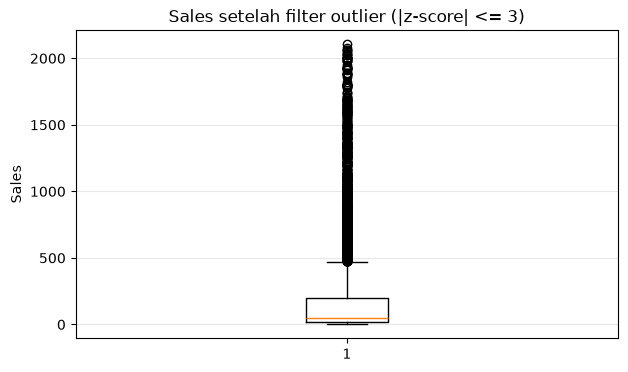

In [15]:
# Menyaring Sales dengan z-score di luar rentang -3 sampai 3.
shape_before = df.shape
sales_zscore = (df["Sales"] - df["Sales"].mean()) / df["Sales"].std(ddof=0)
df = df.loc[sales_zscore.abs() <= 3].copy()

print("Bentuk sebelum:", shape_before)
print("Bentuk sesudah:", df.shape)
print("Jumlah outlier yang dibuang:", shape_before[0] - df.shape[0])

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(df["Sales"])
ax.set_title("Sales setelah filter outlier (|z-score| <= 3)")
ax.set_ylabel("Sales")
ax.grid(axis="y", alpha=0.3)
plt.show()

----

## <div align="center"> Conclusion </div>

### Kesimpulan
Dataset awal berisi 9.800 baris dan 18 kolom. Sebelas nilai kosong hanya terdapat pada `Postal Code`. Question 01 menghapus sebelas baris tersebut, termasuk seluruh baris Vermont, sehingga tersisa 9.789 baris. Karena pengerjaan berurutan, Question 02?06 tidak lagi mengubah bentuk data.

Question 07 menambahkan 48 kolom dummy State bertipe 0/1 dan menghasilkan 9.789 baris ? 66 kolom. Question 08 membuang 122 outlier Sales dengan |z-score| > 3, sehingga tersisa 9.667 baris ? 66 kolom. Box plot menunjukkan sebaran Sales setelah penyaringan.

----

In [16]:
studentName2 = "Nama2"
studentNIM2 = "NIM2"
studentClass2 = "Class2"

In [17]:
print("Name: \t\t{}".format(studentName2))
print("NIM: \t\t{}".format(studentNIM2))
print("NIM: \t\t{}".format(studentClass2))
print("End: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Nama2
NIM: 		NIM2
NIM: 		Class2
End: 		2026-09-15 12:07:14.813178
Device ID: 	50eec467-b0c3-11f1-824e-83db8f6f1918


----

## <div align="center"> Reference </div>

----